## Fichiers
`registered_entities`
`regulatory_case_events`
`site_access_case_events`

In [121]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [122]:
entities = pd.read_csv("registered_entities_cleaned.csv")
regulatory = pd.read_csv("regulatory_case_events_cleaned.csv")
access = pd.read_csv("site_access_case_events.csv")

# Corrélations
## Corrélation sur `registered_entities`

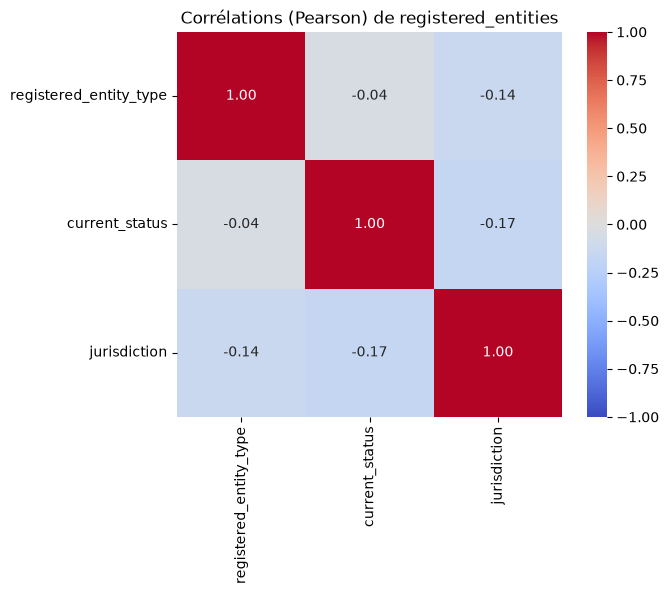

In [123]:
cols_entities = ['registered_entity_type', 'current_status', 'jurisdiction']
df_num = entities[cols_entities].copy()
for col in cols_entities:
    df_num[col] = df_num[col].astype('category').cat.codes

corr = df_num.corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations (Pearson) de registered_entities")
plt.show()

## Corrélations sur `regulatory_case_events`

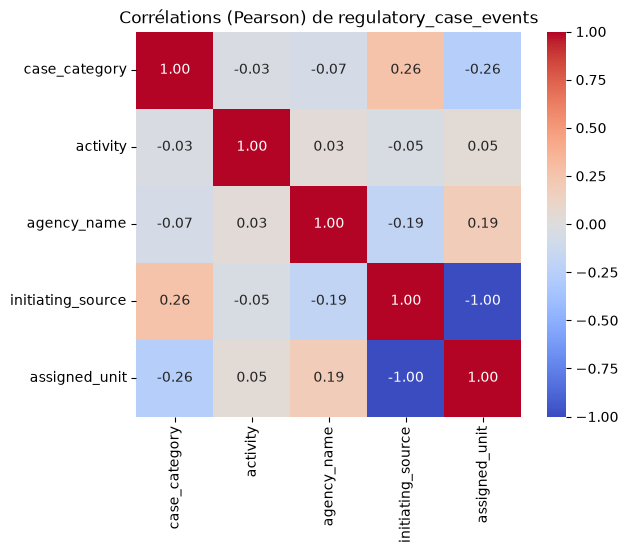

In [124]:
cols_regulatory = ['case_category', 'activity', 'agency_name', 'initiating_source', 'assigned_unit']
df_num = regulatory[cols_regulatory].copy()
for col in cols_regulatory:
    df_num[col] = df_num[col].astype('category').cat.codes

corr = df_num.corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations (Pearson) de regulatory_case_events")
plt.show()

Corrélations sur `site_access_case_events`

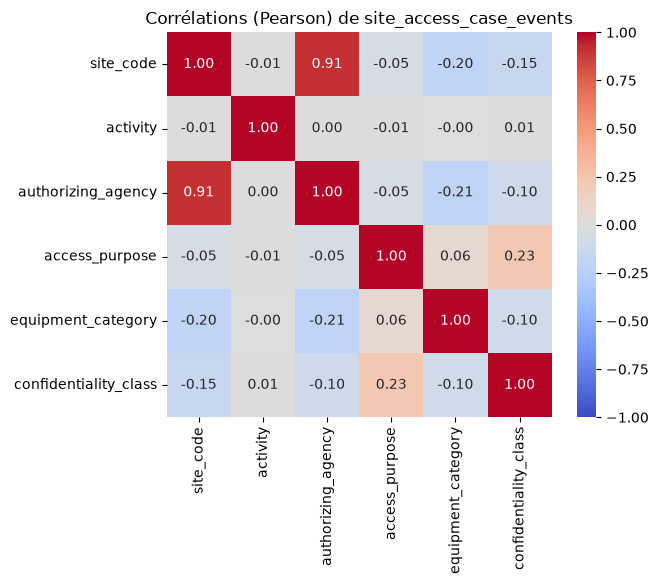

In [125]:
cols_access = ['site_code', 'activity', 'authorizing_agency', 'access_purpose', 'equipment_category', 'confidentiality_class']
df_num = access[cols_access].copy()
for col in cols_access:
    df_num[col] = df_num[col].astype('category').cat.codes

corr = df_num.corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations (Pearson) de site_access_case_events")
plt.show()

# Clustering
## Clustering sur `registered_entities`
Sélection des variables catégorielles pertinentes pour le clustering :

In [126]:
features_df = entities[
    [
        'registered_entity_type',
        'current_status',
        'jurisdiction',
        'registered_address',
    ]
].copy()

# Encodage One-Hot
X_encoded = pd.get_dummies(features_df, drop_first=True)

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

Coude et Silhouette pour trouver le K optimal

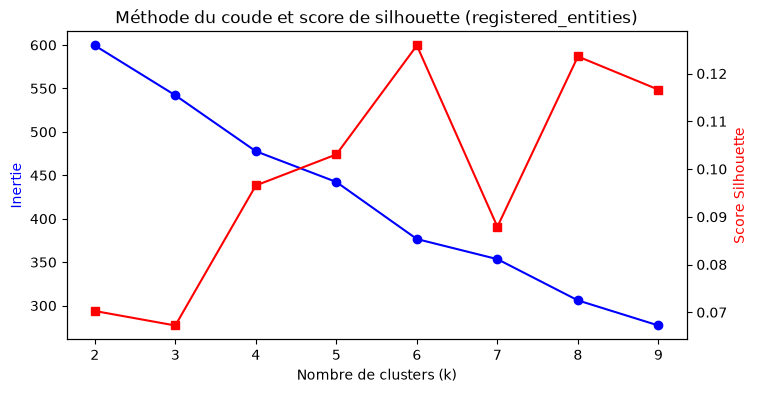

In [127]:
inertias = []
silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=2903, n_init=10)
  labels = kmeans.fit_predict(X_scaled)
  inertias.append(kmeans.inertia_)
  silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(K_range, inertias, 'b-o', label='Inertie')
ax1.set_xlabel('Nombre de clusters (k)')
ax1.set_ylabel('Inertie', color='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, 'r-s', label='Score Silhouette')
ax2.set_ylabel('Score Silhouette', color='r')
plt.title(
    'Méthode du coude et score de silhouette (registered_entities)'
)
plt.show()

On a donc k = 6 (par lecture graphique)

In [128]:
optimal_k = 6

# K-Means
kmeans = KMeans(n_clusters=optimal_k, random_state=2903, n_init=10)
entities['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

# Clustering Hiérarchique (Ward)
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k, metric='euclidean', linkage='ward'
)
entities['cluster_hierarchical'] = hierarchical.fit_predict(X_scaled)

# Comparaison des deux méthodes
print(
    pd.crosstab(
        entities['cluster_kmeans'],
        entities['cluster_hierarchical'],
        rownames=['K-Means'],
        colnames=['Hiérarchique'],
    )
)

Hiérarchique  0  1  2  3  4  5
K-Means                       
0             0  0  0  0  0  2
1             0  8  4  0  0  0
2             0  0  0  1  0  0
3             3  0  0  0  0  0
4             2  0  0  0  0  0
5             0  0  0  0  4  0


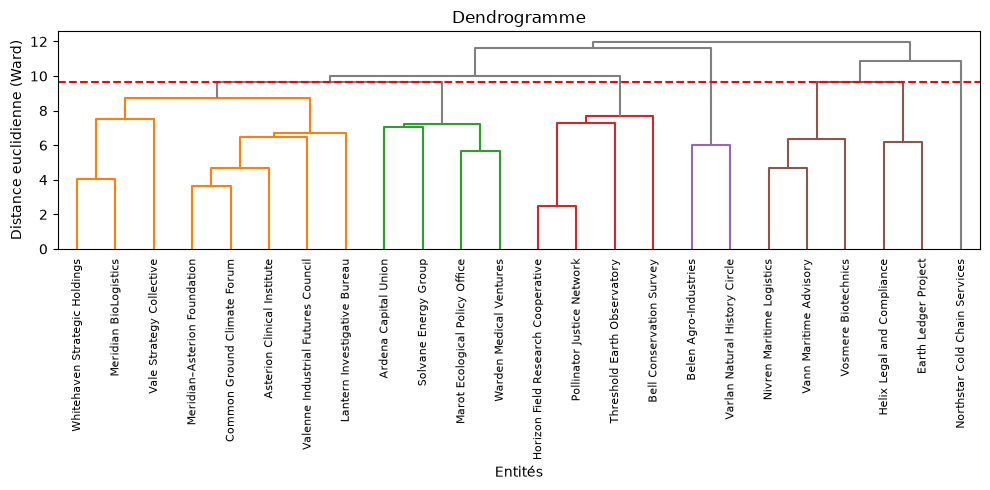

In [129]:
linked = linkage(X_scaled, method='ward')

seuil = (linked[-optimal_k, 2] + linked[-(optimal_k - 1), 2]) / 2


plt.figure(figsize=(10, 5))
dendrogram(
    linked,
    labels=entities['legal_name'].values,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    color_threshold=seuil,
    above_threshold_color="grey",
)
plt.axhline(y=seuil, color="r", linestyle="--", label=f"Coupe à k = {optimal_k}")
plt.title('Dendrogramme')
plt.xlabel('Entités')
plt.ylabel('Distance euclidienne (Ward)')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

Qu'est-ce qui différencie les groupes :

In [130]:
# Moyenne des variables encodées par cluster K-Means pour voir les sur-représentations
analysis_df = pd.DataFrame(X_scaled, columns=X_encoded.columns)
analysis_df['cluster'] = entities['cluster_kmeans']

summary = analysis_df.groupby('cluster').mean()
print(summary.T.head(15))

for c in range(optimal_k):
  print(f'\n Cluster {c}')
  print(entities[entities['cluster_kmeans'] == c][['legal_name', 'registered_entity_type', 'jurisdiction']])

cluster                                              0         1         2  \
registered_entity_type_agricultural_company   2.293659 -0.208514 -0.208514   
registered_entity_type_biotechnology_company -0.208514 -0.208514 -0.208514   
registered_entity_type_consulting_company    -0.447214  0.223607 -0.447214   
registered_entity_type_energy_company        -0.208514  0.208514 -0.208514   
registered_entity_type_financial_institution -0.208514  0.208514 -0.208514   
registered_entity_type_foundation            -0.301511  0.000000 -0.301511   
registered_entity_type_investment_company    -0.208514  0.208514 -0.208514   
registered_entity_type_legal_organization    -0.208514 -0.208514 -0.208514   
registered_entity_type_logistics_company     -0.377964 -0.125988  2.645751   
registered_entity_type_media_organization    -0.208514  0.208514 -0.208514   
registered_entity_type_research_institute     0.718185 -0.307794 -0.512989   
registered_entity_type_trade_association     -0.208514  0.208514

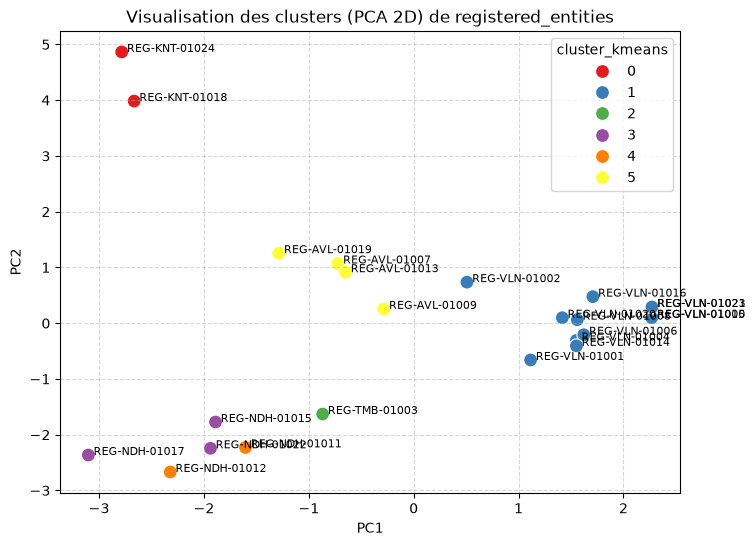

In [131]:
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=entities['cluster_kmeans'],
    palette='Set1',
    s=100,
    data=entities,
)

for i, txt in enumerate(entities['registration_number']):
  plt.annotate(txt, (components[i, 0] + 0.05, components[i, 1]), fontsize=8)

plt.title('Visualisation des clusters (PCA 2D) de registered_entities')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

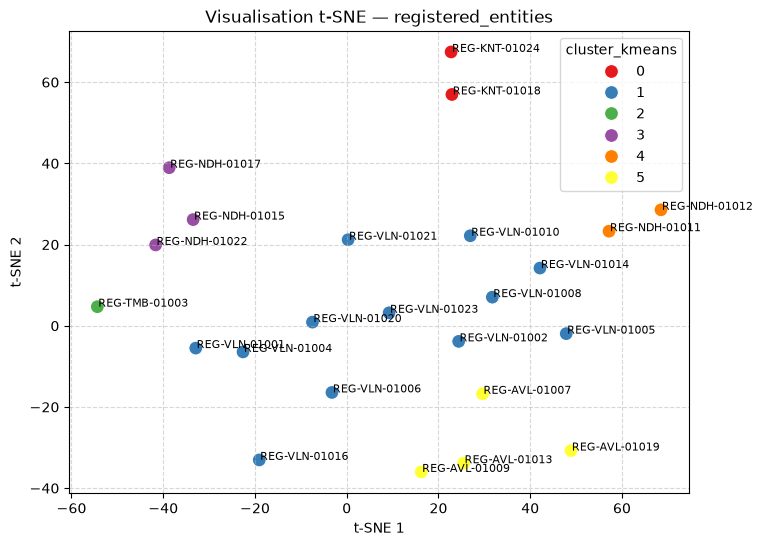

In [132]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=5, random_state=2903, init='pca', learning_rate='auto')
components_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=components_tsne[:, 0],
    y=components_tsne[:, 1],
    hue=entities['cluster_kmeans'],
    palette='Set1',
    s=100,
    data=entities,
)

for i, txt in enumerate(entities['registration_number']):
  plt.annotate(txt, (components_tsne[i, 0] + 0.2, components_tsne[i, 1]), fontsize=8)

plt.title('Visualisation t-SNE — registered_entities')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Clustering sur `regulatory_case_events`

Agrégation par `case_number`

In [133]:
reg_agg = (
    regulatory.groupby('case_number')
    .agg(
        nb_events=('regulatory_event_id', 'count'),
        nb_activities=('activity', 'nunique'),
        nb_outcomes=('outcome', 'nunique'),
        primary_category=('case_category', lambda x: x.mode()[0]),
        primary_agency=('agency_name', lambda x: x.mode()[0]),
        primary_source=('initiating_source', lambda x: x.mode()[0]),
    )
    .reset_index()
)

# Encodage One-Hot des variables catégorielles agrégées
features_reg = reg_agg[
    [
        'nb_events',
        'nb_activities',
        'nb_outcomes',
        'primary_category',
        'primary_agency',
        'primary_source',
    ]
].copy()
X_reg_encoded = pd.get_dummies(features_reg, drop_first=True)

# Standardisation
scaler = StandardScaler()
X_reg_scaled = scaler.fit_transform(X_reg_encoded)

Détermination du K optimal (silhouette score)

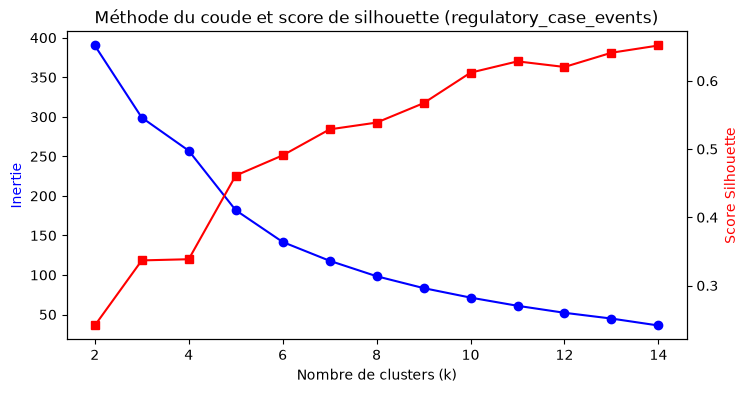

In [134]:
inertias = []
silhouette_scores = []
K_range = range(2, 15)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=2903, n_init=10)
  labels = kmeans.fit_predict(X_reg_scaled)
  inertias.append(kmeans.inertia_)
  silhouette_scores.append(silhouette_score(X_reg_scaled, labels))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(K_range, inertias, 'b-o', label='Inertie')
ax1.set_xlabel('Nombre de clusters (k)')
ax1.set_ylabel('Inertie', color='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, 'r-s', label='Score Silhouette')
ax2.set_ylabel('Score Silhouette', color='r')
plt.title('Méthode du coude et score de silhouette (regulatory_case_events)')
plt.show()

On semble avoir k = 5

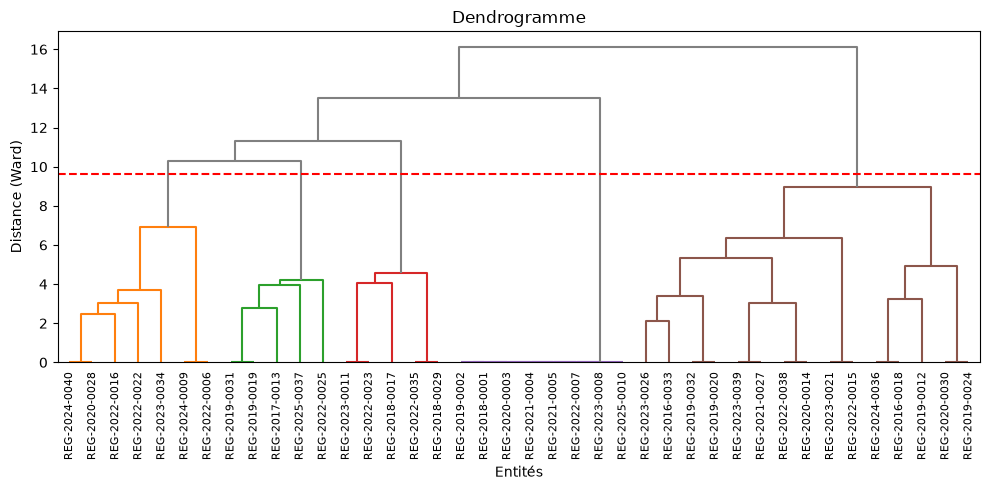

In [135]:
optimal_k = 5
linked = linkage(X_reg_scaled, method='ward')
seuil = (linked[-optimal_k, 2] + linked[-(optimal_k - 1), 2]) / 2

plt.figure(figsize=(10, 5))
dendrogram(
    linked,
    labels=reg_agg['case_number'].values,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    color_threshold=seuil,
    above_threshold_color="grey",
)
plt.axhline(y=seuil, color="r", linestyle="--", label=f"Coupe à k = {optimal_k}")
plt.title('Dendrogramme')
plt.xlabel('Entités')
plt.ylabel('Distance (Ward)')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

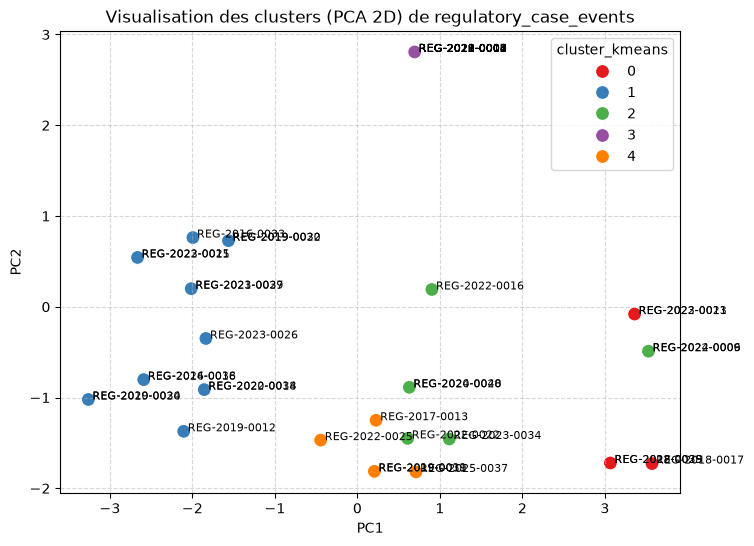

In [136]:
kmeans_reg = KMeans(n_clusters=optimal_k, random_state=2903, n_init=10)
reg_agg['cluster_kmeans'] = kmeans_reg.fit_predict(X_reg_scaled)

pca = PCA(n_components=2)
components = pca.fit_transform(X_reg_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=reg_agg['cluster_kmeans'],
    palette='Set1',
    s=100,
    data=reg_agg,
)

for i, txt in enumerate(reg_agg['case_number']):
  plt.annotate(txt, (components[i, 0] + 0.05, components[i, 1]), fontsize=8)

plt.title('Visualisation des clusters (PCA 2D) de regulatory_case_events')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

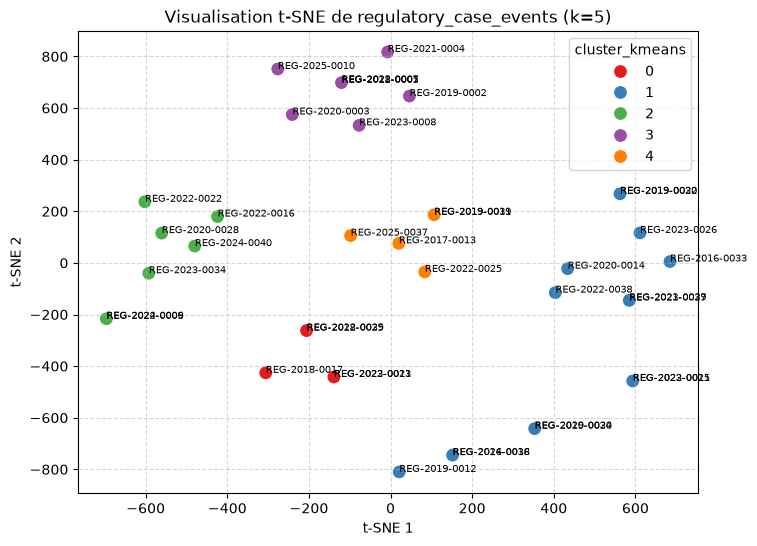

In [137]:
tsne = TSNE(n_components=2, perplexity=min(5, len(reg_agg) - 1), random_state=2903, init='pca', learning_rate='auto')
comp_tsne = tsne.fit_transform(X_reg_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=comp_tsne[:, 0],
    y=comp_tsne[:, 1],
    hue=reg_agg['cluster_kmeans'],
    palette='Set1',
    s=100,
    data=reg_agg,
)
for i, txt in enumerate(reg_agg['case_number']):
  plt.annotate(txt, (comp_tsne[i, 0] + 0.2, comp_tsne[i, 1]), fontsize=7)

plt.title(f'Visualisation t-SNE de regulatory_case_events (k={optimal_k})')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Clustering de `site_access_case_events`

In [138]:
access_agg = (
    access.groupby('access_case_number')
    .agg(
        nb_events=('access_event_id', 'count'),
        nb_activities=('activity', 'nunique'),
        primary_purpose=('access_purpose', lambda x: x.mode()[0]),
        primary_equipment=('equipment_category', lambda x: x.mode()[0]),
        primary_confidentiality=(
            'confidentiality_class',
            lambda x: x.mode()[0],
        ),
        primary_agency=('authorizing_agency', lambda x: x.mode()[0]),
    )
    .reset_index()
)

# Encodage One-Hot des variables catégorielles agrégées
features_acc = access_agg[
    [
        'nb_events',
        'nb_activities',
        'primary_purpose',
        'primary_equipment',
        'primary_confidentiality',
        'primary_agency',
    ]
].copy()
X_acc_encoded = pd.get_dummies(features_acc, drop_first=True)

scaler = StandardScaler()
X_acc_scaled = scaler.fit_transform(X_acc_encoded)

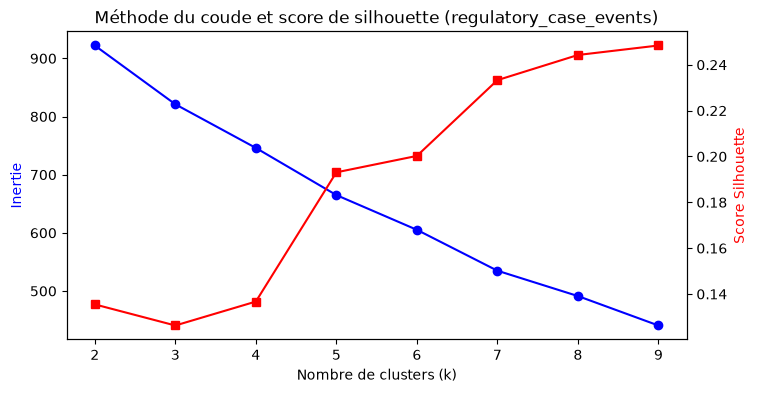

In [139]:
inertias = []
silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=2903, n_init=10)
  labels = kmeans.fit_predict(X_acc_scaled)
  inertias.append(kmeans.inertia_)
  silhouette_scores.append(silhouette_score(X_acc_scaled, labels))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(K_range, inertias, 'b-o', label='Inertie')
ax1.set_xlabel('Nombre de clusters (k)')
ax1.set_ylabel('Inertie', color='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, 'r-s', label='Score Silhouette')
ax2.set_ylabel('Score Silhouette', color='r')
plt.title('Méthode du coude et score de silhouette (regulatory_case_events)')
plt.show()

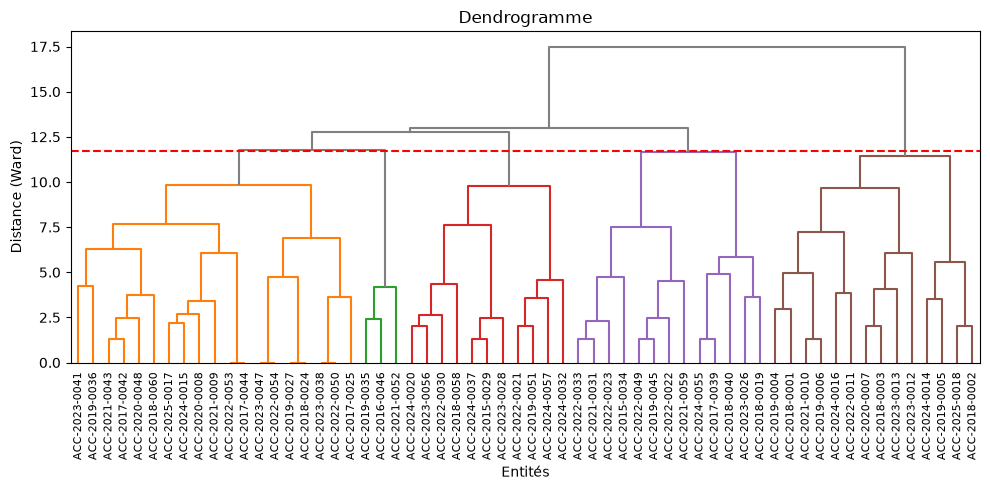

In [140]:
optimal_k = 5
linked = linkage(X_acc_scaled, method='ward')
seuil = (linked[-optimal_k, 2] + linked[-(optimal_k - 1), 2]) / 2

plt.figure(figsize=(10, 5))
dendrogram(
    linked,
    labels=access_agg['access_case_number'].values,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    color_threshold=seuil,
    above_threshold_color="grey",
)
plt.axhline(y=seuil, color="r", linestyle="--", label=f"Coupe à k = {optimal_k}")
plt.title('Dendrogramme')
plt.xlabel('Entités')
plt.ylabel('Distance (Ward)')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

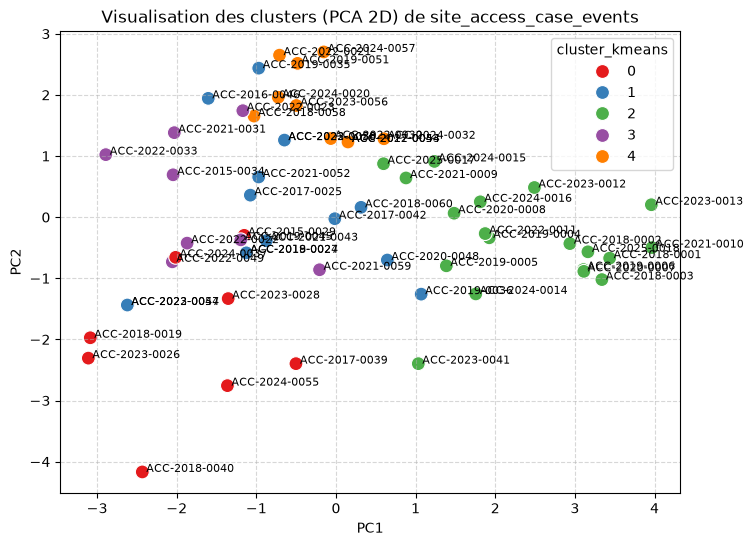

In [141]:
kmeans_acc = KMeans(n_clusters=optimal_k, random_state=2903, n_init=10)
access_agg['cluster_kmeans'] = kmeans_acc.fit_predict(X_acc_scaled)

pca = PCA(n_components=2)
components = pca.fit_transform(X_acc_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=access_agg['cluster_kmeans'],
    palette='Set1',
    s=100,
    data=access_agg,
)

for i, txt in enumerate(access_agg['access_case_number']):
  plt.annotate(txt, (components[i, 0] + 0.05, components[i, 1]), fontsize=8)

plt.title('Visualisation des clusters (PCA 2D) de site_access_case_events')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

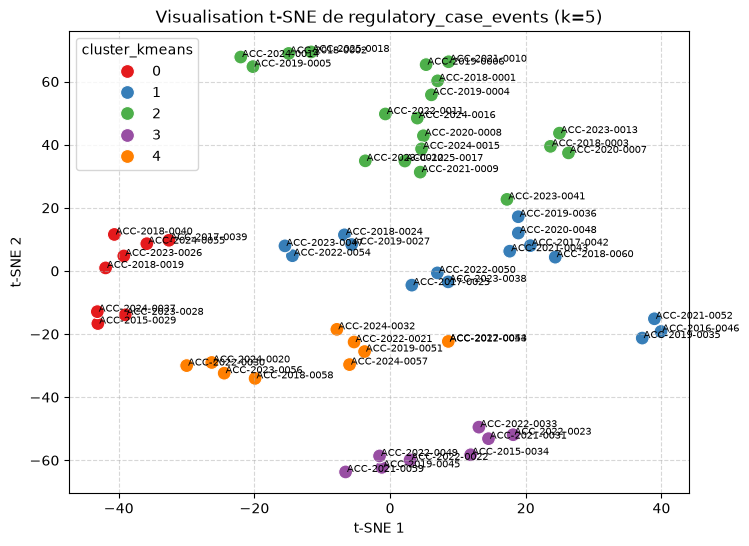

In [142]:
tsne = TSNE(n_components=2, perplexity=min(5, len(access_agg) - 1), random_state=2903, init='pca', learning_rate='auto')
comp_tsne = tsne.fit_transform(X_acc_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=comp_tsne[:, 0],
    y=comp_tsne[:, 1],
    hue=access_agg['cluster_kmeans'],
    palette='Set1',
    s=100,
    data=access_agg,
)
for i, txt in enumerate(access_agg['access_case_number']):
  plt.annotate(txt, (comp_tsne[i, 0] + 0.2, comp_tsne[i, 1]), fontsize=7)

plt.title(f'Visualisation t-SNE de regulatory_case_events (k={optimal_k})')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()